In [141]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [142]:
data = {
    "review_id": list(range(1, 11)),
    "review_text": [
        "The product quality is exceptional, exceeded all my expectations!",
        "Terrible customer service and the item arrived completely damaged.",
        "Average performance, decent for the price point but nothing special.",
        "Absolutely love this! Easy to setup, robust, and works flawlessly.",
        "Stopped working after two days. Extremely disappointed with the purchase.",
        "Customer support helped resolve my setup question within ten minutes.",
        "Delivery was slow and package was missing one adapter cable.",
        "Clean interface and intuitive controls. Highly recommended for students.",
        "Not worth the money, plenty of better alternatives available.",
        "Great value and durable build. Would definitely purchase again."
    ],
    "sentiment": [
        "positive", "negative", "neutral", "positive", "negative",
        "positive", "negative", "positive", "negative", "positive"
    ]
}

df = pd.DataFrame(data)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df)

Dataset loaded successfully!
Dataset shape: (10, 3)


,review_id,review_text,sentiment
0,1,"The product quality is exceptional, exceeded a...",positive
1,2,Terrible customer service and the item arrived...,negative
2,3,"Average performance, decent for the price poin...",neutral
3,4,"Absolutely love this! Easy to setup, robust, a...",positive
4,5,Stopped working after two days. Extremely disa...,negative
5,6,Customer support helped resolve my setup quest...,positive
6,7,Delivery was slow and package was missing one ...,negative
7,8,Clean interface and intuitive controls. Highly...,positive
8,9,"Not worth the money, plenty of better alternat...",negative
9,10,Great value and durable build. Would definitel...,positive


Missing values:
review_id      0
review_text    0
sentiment      0
dtype: int64

Sentiment distribution:
sentiment
positive    5
negative    4
neutral     1
Name: count, dtype: int64


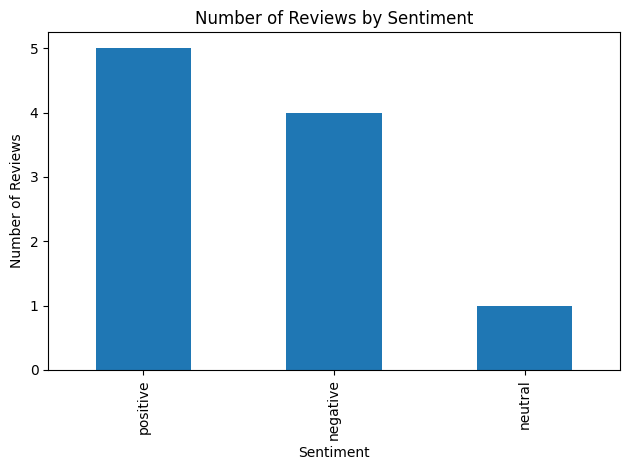

In [143]:
print("Missing values:")
print(df.isnull().sum())

print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

df["sentiment"].value_counts().plot(
    kind="bar",
    title="Number of Reviews by Sentiment",
    xlabel="Sentiment",
    ylabel="Number of Reviews"
)

plt.tight_layout()
plt.show()

In [144]:
import nltk

nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

stop_words = set(stopwords.words("english"))
stop_words -= {"no", "not", "nor"}

lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"<.*?>", " ", text)       # Remove HTML tags
    text = re.sub(r"[^a-z\s]", " ", text)   # Remove punctuation/numbers
    words = text.split()

    words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words
    ]

    return " ".join(words)

df["cleaned_text"] = df["review_text"].apply(clean_text)

display(df[["review_text", "cleaned_text", "sentiment"]])

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


,review_text,cleaned_text,sentiment
0,"The product quality is exceptional, exceeded a...",product quality exceptional exceeded expectation,positive
1,Terrible customer service and the item arrived...,terrible customer service item arrived complet...,negative
2,"Average performance, decent for the price poin...",average performance decent price point nothing...,neutral
3,"Absolutely love this! Easy to setup, robust, a...",absolutely love easy setup robust work flawlessly,positive
4,Stopped working after two days. Extremely disa...,stopped working two day extremely disappointed...,negative
5,Customer support helped resolve my setup quest...,customer support helped resolve setup question...,positive
6,Delivery was slow and package was missing one ...,delivery slow package missing one adapter cable,negative
7,Clean interface and intuitive controls. Highly...,clean interface intuitive control highly recom...,positive
8,"Not worth the money, plenty of better alternat...",not worth money plenty better alternative avai...,negative
9,Great value and durable build. Would definitel...,great value durable build would definitely pur...,positive


In [145]:
X = df["cleaned_text"]
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))

Training reviews: 7
Testing reviews: 3


In [146]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF conversion completed!")
print("Training matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)

TF-IDF conversion completed!
Training matrix shape: (7, 46)
Testing matrix shape: (3, 46)


In [147]:
feature_names = tfidf.get_feature_names_out()

print("First 20 words:")
print(feature_names[:20])

print("\nNumerical TF-IDF matrix:")
print(X_train_tfidf.toarray())

First 20 words:
['absolutely' 'adapter' 'average' 'build' 'cable' 'clean' 'control' 'day'
 'decent' 'definitely' 'delivery' 'disappointed' 'durable' 'easy'
 'exceeded' 'exceptional' 'expectation' 'extremely' 'flawlessly' 'great']

Numerical TF-IDF matrix:
[[0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.4472136  0.4472136  0.4472136  0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.4472136  0.         0.4472136  0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.37796447
  0.37796447 0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.37796447 0.37796447 0.37796447 0.
  0.         0.         0.   

In [148]:
from sklearn.naive_bayes import MultinomialNB

# Create the model
nb_model = MultinomialNB()

# Train the model
nb_model.fit(X_train_tfidf, y_train)

print("Naive Bayes model trained successfully!")

Naive Bayes model trained successfully!


In [149]:
nb_predictions = nb_model.predict(X_test_tfidf)

print("Predicted sentiments:")
print(nb_predictions)

print("\nActual sentiments:")
print(y_test.to_numpy())

Predicted sentiments:
['positive' 'positive' 'positive']

Actual sentiments:
['negative' 'negative' 'positive']


In [150]:
from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression model
lr_model = LogisticRegression(max_iter=1000)

# Train the model
lr_model.fit(X_train_tfidf, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [151]:
lr_predictions = lr_model.predict(X_test_tfidf)

print("Logistic Regression predictions:")
print(lr_predictions)

print("\nActual sentiments:")
print(y_test.to_numpy())

Logistic Regression predictions:
['positive' 'positive' 'positive']

Actual sentiments:
['negative' 'negative' 'positive']


In [152]:
from sklearn.metrics import accuracy_score

nb_accuracy = accuracy_score(y_test, nb_predictions)
lr_accuracy = accuracy_score(y_test, lr_predictions)

print("Naive Bayes Accuracy:", round(nb_accuracy * 100, 2), "%")
print("Logistic Regression Accuracy:", round(lr_accuracy * 100, 2), "%")

Naive Bayes Accuracy: 33.33 %
Logistic Regression Accuracy: 33.33 %


In [153]:
def predict_sentiment(review):
    # Clean the input review
    cleaned_review = clean_text(review)

    # Convert text into TF-IDF features
    review_tfidf = tfidf.transform([cleaned_review])

    # Predict sentiment using both models
    nb_prediction = nb_model.predict(review_tfidf)[0]
    lr_prediction = lr_model.predict(review_tfidf)[0]

    print("Customer Review:", review)
    print("Naive Bayes Prediction:", nb_prediction)
    print("Logistic Regression Prediction:", lr_prediction)

    return nb_prediction, lr_prediction

print("Prediction function created successfully!")

Prediction function created successfully!


In [154]:
predict_sentiment(
    "Excellent product! Great quality and amazing performance."
)

Customer Review: Excellent product! Great quality and amazing performance.
Naive Bayes Prediction: positive
Logistic Regression Prediction: positive


(np.str_('positive'), 'positive')

In [155]:
predict_sentiment(
    "Terrible product. It broke quickly and I am very disappointed."
)

Customer Review: Terrible product. It broke quickly and I am very disappointed.
Naive Bayes Prediction: positive
Logistic Regression Prediction: positive


(np.str_('positive'), 'positive')

In [156]:
predict_sentiment(
    "The product works as expected and has average features."
)

Customer Review: The product works as expected and has average features.
Naive Bayes Prediction: positive
Logistic Regression Prediction: positive


(np.str_('positive'), 'positive')

In [157]:
from sklearn.metrics import classification_report

print("NAIVE BAYES REPORT")
print(classification_report(
    y_test,
    nb_predictions,
    zero_division=0
))

print("LOGISTIC REGRESSION REPORT")
print(classification_report(
    y_test,
    lr_predictions,
    zero_division=0
))

NAIVE BAYES REPORT
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         2
    positive       0.33      1.00      0.50         1

    accuracy                           0.33         3
   macro avg       0.17      0.50      0.25         3
weighted avg       0.11      0.33      0.17         3

LOGISTIC REGRESSION REPORT
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         2
    positive       0.33      1.00      0.50         1

    accuracy                           0.33         3
   macro avg       0.17      0.50      0.25         3
weighted avg       0.11      0.33      0.17         3

